# IntroStat Week 8

Welcome to the 8th lecture in IntroStat

During the lectures we will present both slides and notebooks. 

This is the notebook used in the lecture in week 8.


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.power as smp


### Example: Height and weight

Linear regression with height and weight data

In [34]:
# data
x = np.array([168, 161, 167, 179, 184, 166, 198, 187, 191, 179])             # height data
y = np.array([65.5, 58.3, 68.1, 85.7, 80.5, 63.4, 102.6, 91.4, 86.7, 78.9])  # weight data

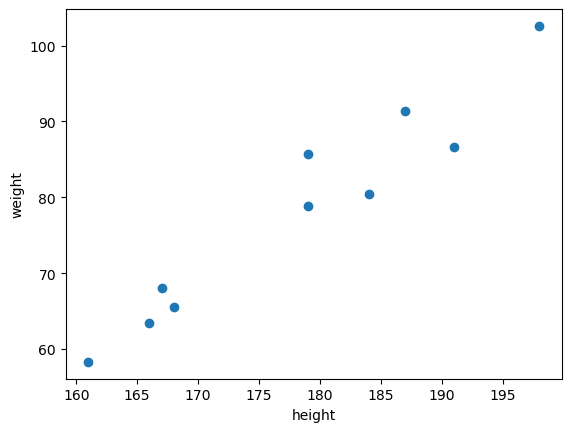

In [35]:
# make scatter plot:
plt.scatter(x,y)
plt.ylabel("weight")
plt.xlabel("height")
plt.show()

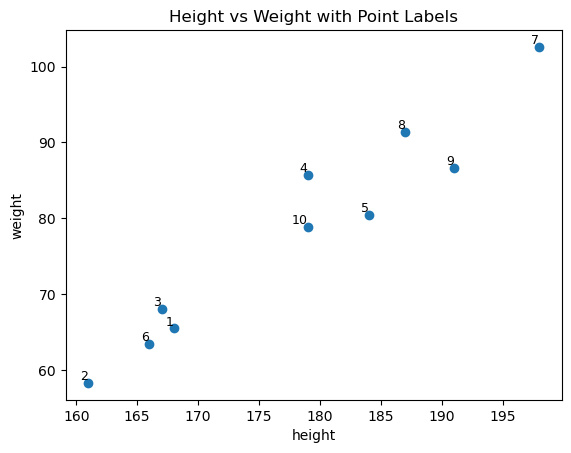

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# data
x = np.array([168, 161, 167, 179, 184, 166, 198, 187, 191, 179])             # height data
y = np.array([65.5, 58.3, 68.1, 85.7, 80.5, 63.4, 102.6, 91.4, 86.7, 78.9])  # weight data

# make scatter plot
plt.scatter(x, y)

# label each point with its sequence number (1–10)
for i in range(len(x)):
    plt.text(x[i], y[i], str(i+1), fontsize=9, ha='right', va='bottom')

plt.ylabel("weight")
plt.xlabel("height")
plt.title("Height vs Weight with Point Labels")
plt.show()

Linear relationship?

Now lets put data into a **pandas dataframe**:

In [37]:
student = pd.DataFrame({'x': x, 'y': y})  # "import pandas as pd"
print(student)

     x      y
0  168   65.5
1  161   58.3
2  167   68.1
3  179   85.7
4  184   80.5
5  166   63.4
6  198  102.6
7  187   91.4
8  191   86.7
9  179   78.9


Now we do a **linear regression model**:

In [38]:
# for now we just run the code, we will understand it later

# fit the model
fitStudents = smf.ols(formula = 'y ~ x', data=student).fit()  # OBS: use the statsmodels.formula.api library (smf)

# Get prediction and confidence intervals
x_pred = pd.DataFrame({'x': np.arange(160,200, 1)})
pred = fitStudents.get_prediction(x_pred).summary_frame(alpha=0.05)

plt.scatter(x,y)
# label each point with its sequence number (1–10)for i in range(len(x)):
    plt.text(x[i], y[i], str(i+1), fontsize=9, ha='right', va='bottom')

plt.plot(x_pred, pred["mean"], color="red")
plt.ylabel("weight")
plt.xlabel("height")
plt.show()

IndentationError: unexpected indent (269967503.py, line 12)

The red line is the **regression line**.

The regression line is a straight line.



It is defined by a **slope** and an **intercept** with the y-axis.

In [ ]:
# later today we will be able to estimate values for the parameters: intercept and slope
# we will also learn to make a "Regression Results Table" with Python (using smf library)
print(fitStudents.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.924
No. Observations:                  10   F-statistic:                     110.3
Covariance Type:            nonrobust   Prob (F-statistic):           5.87e-06
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -119.9581     18.897     -6.348      0.000    -163.535     -76.381
x              1.1127      0.106     10.504      0.000       0.868       1.357

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.75e+03. This might indicate that there are
strong multicollinearity or other numerical problems.


c:\Users\skhalid\Miniconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


The table includes a lot of information and we will understand almost all of it by the end of today :)

We will also be able to estimate **standard errors** and **conficence intervals** for the parameters of the model (also in table above)

Later today we will be able to make a **prediction interval** for "future" **observations** (with other x-values)

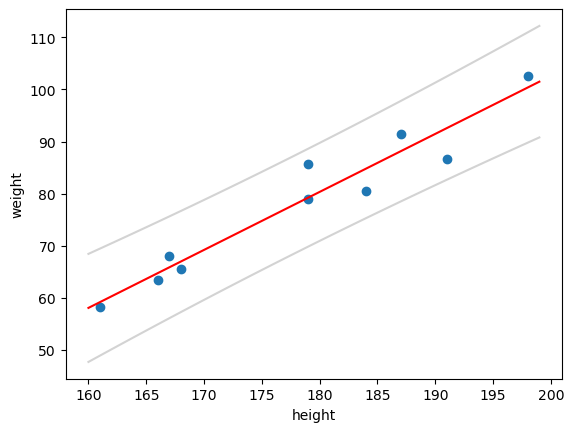

In [ ]:
# later today we will be able to make a prediction interval for "future" obervations (with other x-values)
plt.scatter(x,y)
plt.plot(x_pred, pred["mean"], color="red")
plt.plot(x_pred, pred["obs_ci_lower"], color="lightgrey")
plt.plot(x_pred, pred["obs_ci_upper"], color="lightgrey")
plt.ylabel("weight")
plt.xlabel("height")
plt.show()


and later today we will also be able to make a **confidence interval** for the mean at every value on the x-axis (*confidence interval for the line*)

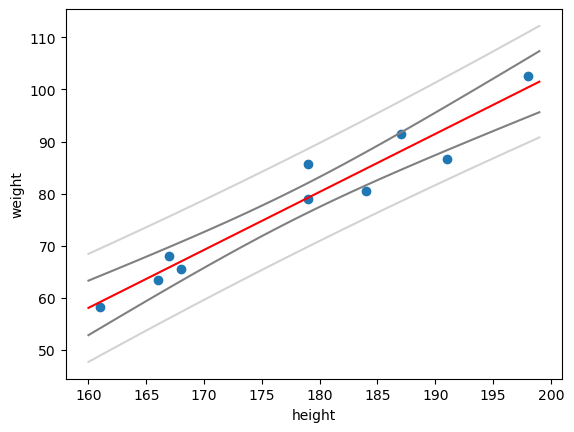

In [ ]:
# and later today we will also be able to make a prediction interval for the mean at every value on the x-axis
plt.scatter(x,y)
plt.plot(x_pred, pred["mean"], color="red")
plt.plot(x_pred, pred["mean_ci_lower"], color="grey")
plt.plot(x_pred, pred["mean_ci_upper"], color="grey")
plt.plot(x_pred, pred["obs_ci_lower"], color="lightgrey")
plt.plot(x_pred, pred["obs_ci_upper"], color="lightgrey")
plt.ylabel("weight")
plt.xlabel("height")
plt.show()


Other things we will talk about:

1) How does correlation relate to the linear regression (slope)?
2) How much of the total variation in y is explained by the linear relationship?

(back to slides)

### Example: Estimating parameters $\beta_0$ and $\beta_1$

Simulated data:

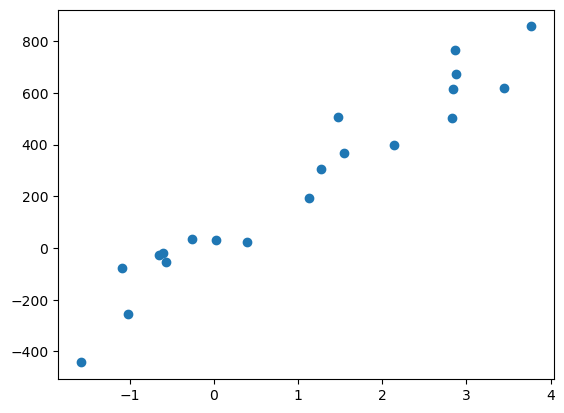

In [ ]:
# First we compute some simulated data, so we know the "real" beta_0 and beta_1 (and sigma)
#np.random.seed(23498)

beta_0 = 50
beta_1 = 200
sigma = 90

# choose som random x-values:
x = stats.uniform.rvs(size = 20, loc=-2, scale = 6)
# simulate y-values from statistical model:
y = beta_0 + beta_1*x + stats.norm.rvs(size = 20, loc=0, scale = sigma)

plt.scatter(x,y)
plt.show()

This is now our "Toy Data" :-)

Lets see if we can estimate the parameters 

In [ ]:
# calculate estimates beta_0_hat and beta_1_hat:
Sxx = np.sum((x - x.mean())**2)

beta_1_hat = np.sum((x - x.mean())*(y - y.mean())) / Sxx
beta_0_hat = y.mean() - beta_1_hat*x.mean()

print(beta_0_hat, beta_1_hat)
print(beta_0, beta_1)

36.66002184157662 205.64673616202424
50 200


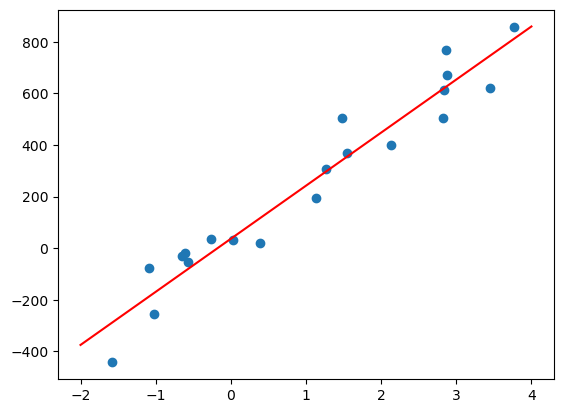

In [ ]:
# plot estimated model with data:
plt.scatter(x,y)
plt.plot([-2,4], [beta_0_hat + beta_1_hat*(-2), beta_0_hat + beta_1_hat*(4)], color="red")
plt.show()


Great! 

also plot the "true" underlying model (this is *only* possible because we have simulated data - IRL one cannot plot the "true" model):

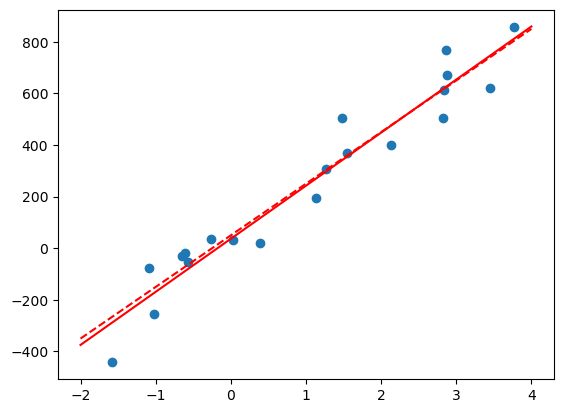

In [ ]:
# also plot the "true" underlying model (this is *only* possible because we have simulated data - IRL one cannot plot the "true" model):
plt.scatter(x,y)
plt.plot([-2,4], [beta_0_hat + beta_1_hat*(-2), beta_0_hat + beta_1_hat*(4)], color="red")
plt.plot([-2,4], [beta_0 + beta_1*(-2), beta_0 + beta_1*(4)], color="red", linestyle='--')
plt.show()

We can also estimate the variance of residuals:

In [ ]:
res = y - beta_0_hat - beta_1_hat * x
sigma_hat = np.sqrt(np.sum(res**2)/(20-2))
print(sigma_hat)

93.26864504565216


Compare this value to the real underlying sigma, which was 90 :)

(back to slides)

### Example: Variation of parameter estimates ($\beta_0$ and $\beta_1$)

Simulating **many** samples from the underlying known model

-5.420095643740268 224.24940397818415


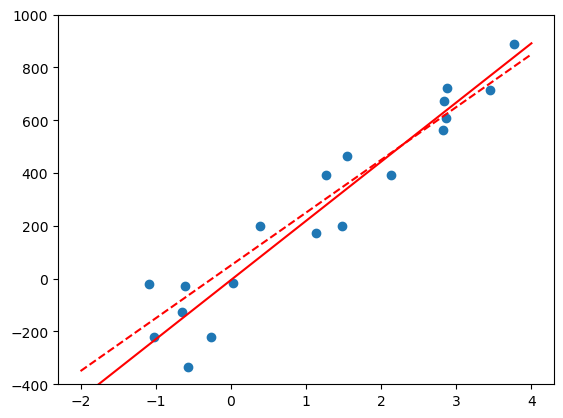

In [ ]:
# repeat with new sample:
y = beta_0 + beta_1*x + stats.norm.rvs(size = 20, loc=0, scale = sigma) # y-data with new values of residuals

# re-calculate parameters
Sxx = np.sum((x - x.mean())**2)
beta_1_hat = np.sum((x - x.mean())*(y - y.mean())) / Sxx
beta_0_hat = y.mean() - beta_1_hat*x.mean()
print(beta_0_hat, beta_1_hat)

#plot:
plt.scatter(x,y)
plt.plot([-2,4], [beta_0_hat + beta_1_hat*(-2), beta_0_hat + beta_1_hat*(4)], color="red")
plt.plot([-2,4], [beta_0 + beta_1*(-2), beta_0 + beta_1*(4)], color="red", linestyle='--')
plt.ylim([-400,1000])
plt.show()

Run the cell above several times

Observe how the estimated model changes due to fluctuations in data

(back to slides)

### Example: Estimate standard errors of the parameters (height and weight data)

In [ ]:
# Recall the height and weigth data:
print(student)

     x      y
0  168   65.5
1  161   58.3
2  167   68.1
3  179   85.7
4  184   80.5
5  166   63.4
6  198  102.6
7  187   91.4
8  191   86.7
9  179   78.9


In [ ]:
### 1 ###  Estimate parameters beta_0_hat and bata_1_hat *manually*

Sxx = np.sum((student["x"] - student["x"].mean())**2)

beta_1_hat = np.sum((student["x"] - student["x"].mean())*(student["y"] - student["y"].mean())) / Sxx

beta_0_hat = student["y"].mean() - beta_1_hat*student["x"].mean()

print(beta_0_hat, beta_1_hat)

-119.95810730253355 1.11274217585693


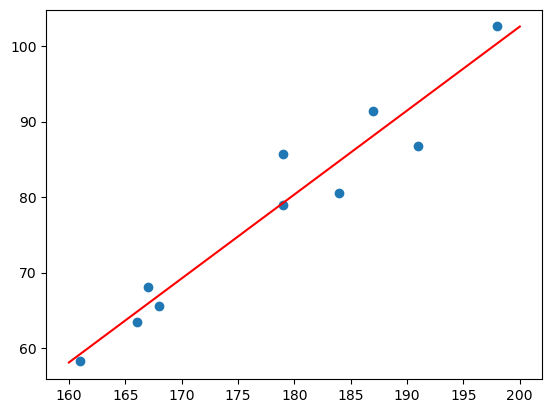

In [ ]:
# plot:
plt.scatter(student["x"], student["y"])  # plot the data
plt.plot([160, 200], [beta_0_hat + beta_1_hat*160, beta_0_hat + beta_1_hat*200], color="red")  # plot the line (from 160 to 200)
plt.show()

In [ ]:
### 2 ###  Estimate standard error for the parameters *manually* 

# first we add some columns to the dataset:
student["y_pred"] = beta_0_hat + beta_1_hat*student["x"]  # y-values ON the regression line
student["residuals"] = student["y"] - student["y_pred"]   # residuals
print(student)

     x      y      y_pred  residuals
0  168   65.5   66.982578  -1.482578
1  161   58.3   59.193383  -0.893383
2  167   68.1   65.869836   2.230164
3  179   85.7   79.222742   6.477258
4  184   80.5   84.786453  -4.286453
5  166   63.4   64.757094  -1.357094
6  198  102.6  100.364844   2.235156
7  187   91.4   88.124680   3.275320
8  191   86.7   92.575648  -5.875648
9  179   78.9   79.222742  -0.322742


### Theorem 5.8 (second part)
Since ${\sigma}^2$ is unknown, we use the central estimate for ${\sigma}^2$


$\hat{\sigma}^2 = \frac{RSS(\hat{\beta}_0, \hat{\beta}_1)}{n - 2} = \frac{\sum_{i=1}^n e_i^2}{n - 2}$

where:
- $ \hat{\sigma}^2 $ is the estimated variance of the errors,
- $ RSS(\hat{\beta}_0, \hat{\beta}_1) $ is the residual sum of squares for the estimates $\hat{\beta}_0$ and $\hat{\beta}_1$,
- $ n $ is the number of observations,
- $ e_i $ represents the residuals (errors) for each observation $ i $.

$\hat{\sigma}_{\beta_0} = \hat{\sigma} \sqrt{\frac{1}{n} + \frac{\bar{x}^2}{S_{xx}}}$

$\hat{\sigma}_{\beta_1} = \hat{\sigma} \sqrt{\frac{1}{S_{xx}}}$

In [ ]:
RSS = np.sum(student["residuals"]**2)
sigma_hat = np.sqrt(RSS/(10-2))

se_beta_0_hat = sigma_hat*np.sqrt(1/10 + student["x"].mean()**2 / Sxx)

se_beta_1_hat = sigma_hat*np.sqrt(1/Sxx)

print("Intercept: ", beta_0_hat, se_beta_0_hat)
print("slope:     ", beta_1_hat, se_beta_1_hat)

Intercept:  -119.95810730253355 18.897051763916973
slope:      1.11274217585693 0.10593909266894098


In [ ]:
### automatic ###  Do it all with inbuilt python function smf.ols
fitStudents = smf.ols(formula = 'y ~ x', data=student).fit()  # OBS: use the statsmodels.formula.api library (smf)
print(fitStudents.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.924
No. Observations:                  10   F-statistic:                     110.3
Covariance Type:            nonrobust   Prob (F-statistic):           5.87e-06
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -119.9581     18.897     -6.348      0.000    -163.535     -76.381
x              1.1127      0.106     10.504      0.000       0.868       1.357

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.75e+03. This might indicate that there are
strong multicollinearity or other numerical problems.


c:\Users\skhalid\Miniconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


In [ ]:
# Get parameters
print(fitStudents.params)

Intercept   -119.958107
x              1.112742
dtype: float64


In [ ]:
# Get parameter standard errors
print(fitStudents.bse)

Intercept    18.897052
x             0.105939
dtype: float64


In [ ]:
# get estimate of sigma^2:
print(fitStudents.scale)
print(sigma_hat**2) #compare to the one we calculated *manualy*

15.061388599105827
15.06138859910578


In [ ]:
# get fitted values:
print(fitStudents.fittedvalues)

0     66.982578
1     59.193383
2     65.869836
3     79.222742
4     84.786453
5     64.757094
6    100.364844
7     88.124680
8     92.575648
9     79.222742
dtype: float64


(compare with the "y_pred" values that we have computed above)

(back to slides)

### Example: Hypothesis test for parameters

In [ ]:
fitStudents = smf.ols(formula = 'y ~ x', data=student).fit()  # OBS: use the statsmodels.formula.api library (smf)
print(fitStudents.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.924
No. Observations:                  10   F-statistic:                     110.3
Covariance Type:            nonrobust   Prob (F-statistic):           5.87e-06
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -119.9581     18.897     -6.348      0.000    -163.535     -76.381
x              1.1127      0.106     10.504      0.000       0.868       1.357

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.75e+03. This might indicate that there are
strong multicollinearity or other numerical problems.


c:\Users\skhalid\Miniconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


In [ ]:
# Warning!! The p-values appear to be zero but they are in reality only smaller than 0.000

# print the pvalues seperately to be sure:
print(fitStudents.pvalues)

Intercept    0.000221
x            0.000006
dtype: float64


In [ ]:
# we can also do the test manually (here only for the intercept):

# calculate "t_obs"
t_obs_int = -119.9581/18.897
print(t_obs_int)

-6.347997036566651


In [ ]:
# find corresponding p-value:
print(2*stats.t.cdf(t_obs_int, df=10-2))  # obs! df = n - 2  (2 is the number of parameters)

0.00022108433338164315


(back to slides)

### Example: Confidence interval for parameters

In [ ]:
fitStudents = smf.ols(formula = 'y ~ x', data=student).fit()  
print(fitStudents.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.924
No. Observations:                  10   F-statistic:                     110.3
Covariance Type:            nonrobust   Prob (F-statistic):           5.87e-06
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -119.9581     18.897     -6.348      0.000    -163.535     -76.381
x              1.1127      0.106     10.504      0.000       0.868       1.357

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.75e+03. This might indicate that there are
strong multicollinearity or other numerical problems.


c:\Users\skhalid\Miniconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


KAHOOT! (x1)

In [ ]:
# we can also calculate CI *manually*

# here only for the intercept:

print(-119.9581 - stats.t.ppf(0.975, df=10-2)*18.897)
print(-119.9581 + stats.t.ppf(0.975, df=10-2)*18.897)

-163.53466014295313
-76.38153985704687


(back to slides)

### Example: Confidence interval for the line

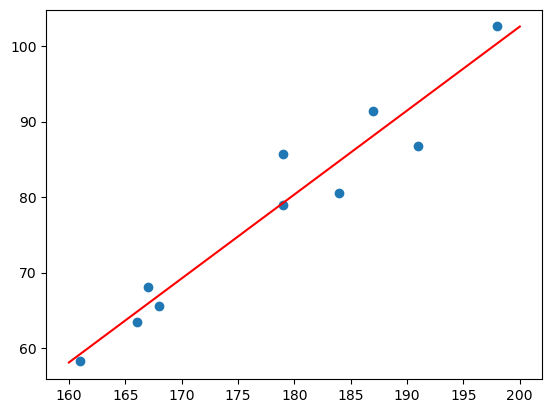

In [ ]:
# Recall data and model:
plt.scatter(student["x"], student["y"])  # plot the data
plt.plot([160, 200], [beta_0_hat + beta_1_hat*160, beta_0_hat + beta_1_hat*200], color="red")  # plot the line (from 160 to 200)
plt.show()

Lets make predictions of (mean) weight for some other height-values. 

What is the mean weight for persons of height 170cm, 175cm, 195cm or 205 cm?

We can calculate this manually (y = beta0_hat + beta1_hat * x)

But we can also use Python:

In [ ]:
# Make predictions (= mean y-value at a given x-value) and corresponding confidence intervals 
x_new = pd.DataFrame({'x': [170, 175, 195, 205]})

pred = fitStudents.get_prediction(x_new).summary_frame(alpha=0.05) 

print(pred.head())

         mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0   69.208063  1.491448      65.768778      72.647348     59.620573   
1   74.771773  1.267733      71.848376      77.695171     65.357023   
2   97.026617  2.179361      92.001003     102.052231     86.762696   
3  108.154039  3.112519     100.976558     115.331520     96.682007   

   obs_ci_upper  
0     78.795552  
1     84.186524  
2    107.290538  
3    119.626070  


The column "mean" is the predicted mean weight for each height in x_new

We also get a standard error for the mean weight (mean_se) and a conficence interval (for the specified alpha = 0.05)

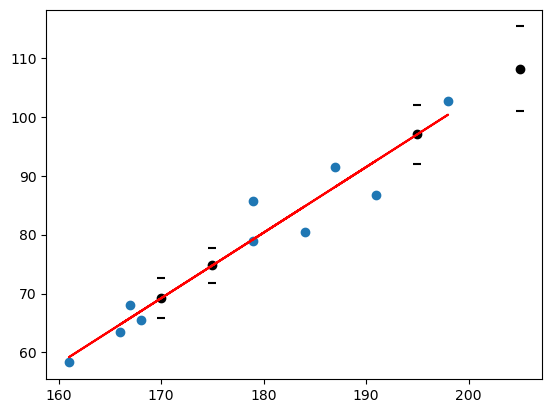

In [ ]:
# Plot the new predictions of mean weight:

plt.scatter(student["x"], student["y"])
plt.plot(student["x"], student["y_pred"], color="red")
plt.scatter(x_new, pred["mean"], color="black")
plt.scatter(x_new, pred["mean_ci_lower"], color="black", marker="_")
plt.scatter(x_new, pred["mean_ci_upper"], color="black", marker="_")
plt.show()

Notice how the confidence interval i larger for more "extreme" heights

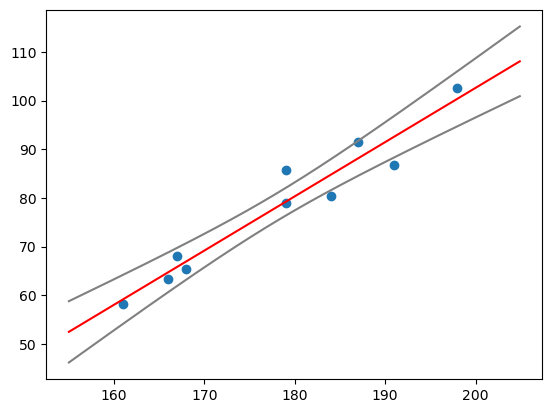

In [ ]:
# plot the confidence interval for large range of values:

x_new = pd.DataFrame({'x': np.arange(155, 205,0.1)})
pred = fitStudents.get_prediction(x_new).summary_frame(alpha=0.05) 

plt.scatter(student["x"],student["y"])
plt.plot(x_new, pred["mean"], color="red")
plt.plot(x_new, pred["mean_ci_lower"], color="grey")
plt.plot(x_new, pred["mean_ci_upper"], color="grey")
plt.show()

We could also calculate this interval *manually* (see Method 5.18)

(back to slides)

### Example: Prediction interval for parameters

In [ ]:
# Same data as above

# now we want the prediction interval for individual (new/future) observations

print(pred.head())

        mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
0  52.516930  2.728214      46.225656      58.808204     41.577488   
1  52.628204  2.718757      46.358739      58.897669     41.701290   
2  52.739478  2.709308      46.491803      58.987154     41.825051   
3  52.850753  2.699868      46.624847      59.076659     41.948772   
4  52.962027  2.690436      46.757871      59.166183     42.072453   

   obs_ci_upper  
0     63.456372  
1     63.555119  
2     63.653906  
3     63.752733  
4     63.851601  


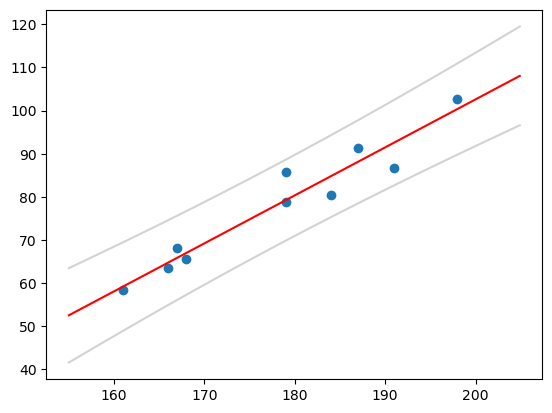

In [ ]:
# plot the predictions intervals for a wide range of x-values:
plt.scatter(student["x"],student["y"])
plt.plot(x_new, pred["mean"], color="red")
plt.plot(x_new, pred["obs_ci_lower"], color="lightgrey")
plt.plot(x_new, pred["obs_ci_upper"], color="lightgrey")
plt.show()

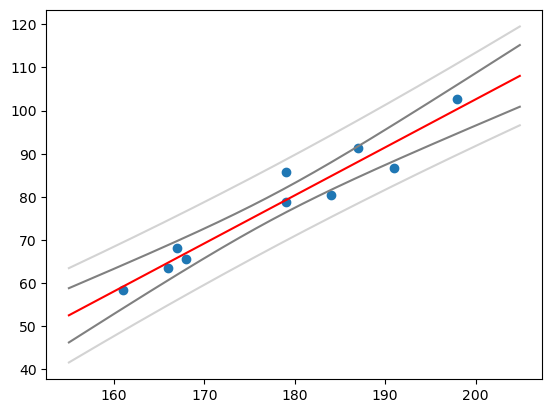

In [ ]:
# Compare the prediction interval and the confidence interval
plt.scatter(student["x"],student["y"])
plt.plot(x_new, pred["mean"], color="red")
plt.plot(x_new, pred["obs_ci_lower"], color="lightgrey")
plt.plot(x_new, pred["obs_ci_upper"], color="lightgrey")
plt.plot(x_new, pred["mean_ci_lower"], color="grey")
plt.plot(x_new, pred["mean_ci_upper"], color="grey")
plt.show()

(back to slides)

### Example: Correlation and $R^2$

In [ ]:
# Recall student height and weight data
print(student)

     x      y      y_pred  residuals
0  168   65.5   66.982578  -1.482578
1  161   58.3   59.193383  -0.893383
2  167   68.1   65.869836   2.230164
3  179   85.7   79.222742   6.477258
4  184   80.5   84.786453  -4.286453
5  166   63.4   64.757094  -1.357094
6  198  102.6  100.364844   2.235156
7  187   91.4   88.124680   3.275320
8  191   86.7   92.575648  -5.875648
9  179   78.9   79.222742  -0.322742


In [ ]:
fitStudents = smf.ols(formula = 'y ~ x', data=student).fit()  # OBS: use the statsmodels.formula.api library (smf)
print(fitStudents.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.924
No. Observations:                  10   F-statistic:                     110.3
Covariance Type:            nonrobust   Prob (F-statistic):           5.87e-06
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -119.9581     18.897     -6.348      0.000    -163.535     -76.381
x              1.1127      0.106     10.504      0.000       0.868       1.357

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.75e+03. This might indicate that there are
strong multicollinearity or other numerical problems.


c:\Users\skhalid\Miniconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


In [ ]:
print(np.corrcoef(student["x"], student["y"]))
print(np.corrcoef(student["x"], student["y"])**2)

[[1.         0.96560343]
 [0.96560343 1.        ]]
[[1.         0.93238999]
 [0.93238999 1.        ]]


compare with R-squared in the table

### Example: Model validation in Python

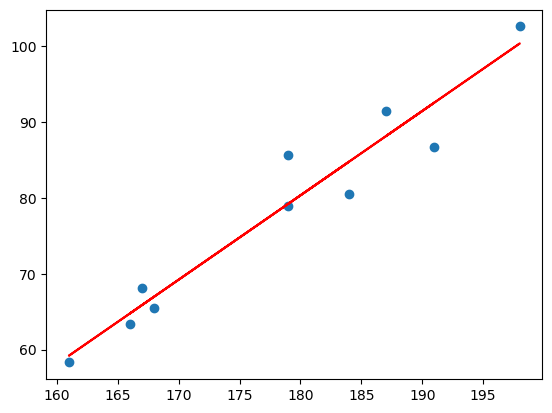

In [ ]:
plt.scatter(student["x"], student["y"])
plt.plot(student["x"], fitStudents.fittedvalues, color="red")
plt.show()

Inspect the residuals (and assumption about normality):

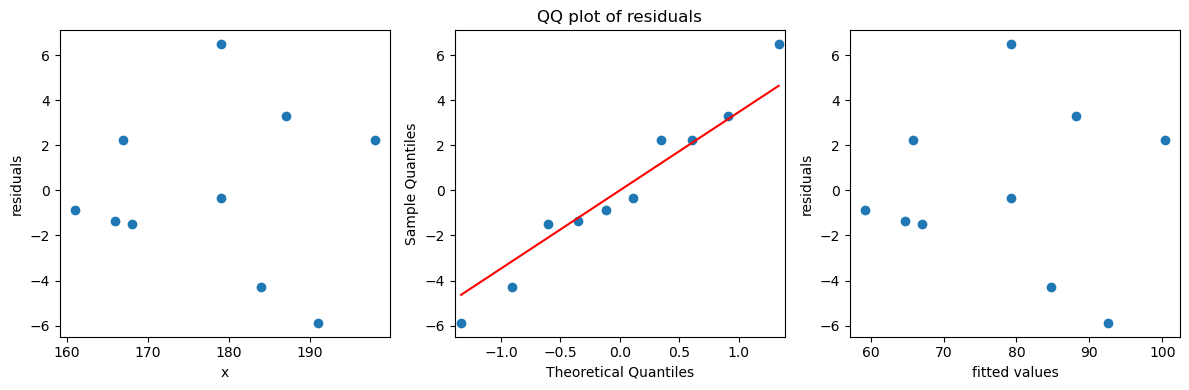

In [ ]:
# residuals:
residuals = fitStudents.resid
fittedvalues = fitStudents.fittedvalues

fig, (ax0, ax1, ax2) = plt.subplots(1,3,figsize=(12,4))

# plot residuals versus x-values:
ax0.scatter(student["x"],student["residuals"])
ax0.set_xlabel("x")
ax0.set_ylabel("residuals")

# qq-plot of resiudals:
sm.qqplot(residuals,ax=ax1, line='s')
ax1.set_title("QQ plot of residuals")

# plot residuals versus fitted values:
ax2.scatter(fittedvalues,residuals)
ax2.set_xlabel("fitted values")
ax2.set_ylabel("residuals")

plt.tight_layout()
plt.show()


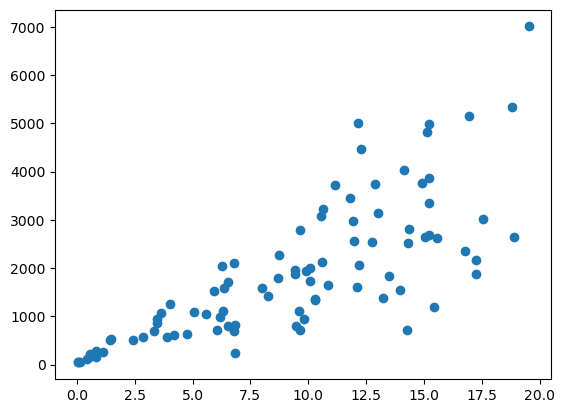

In [ ]:
# Another example:

beta_0 = 50
beta_1 = 200
sigma = 90

# choose som random x-values:
x = stats.uniform.rvs(size = 90, loc=0, scale = 20)
# simulate y-values from statistical model:
y = beta_0 + beta_1*x + x*stats.norm.rvs(size = 90, loc=0, scale = sigma)

plt.scatter(x,y)
plt.show()

Is the normal assumption fulfilled here??

In [ ]:

data = pd.DataFrame({'x': x, 'y': y})  # OBS: use the pandas library (pd)
linfit = smf.ols(formula = 'y ~ x', data=data).fit()

data["residuals"] = linfit.resid
fittedvalues = linfit.fittedvalues


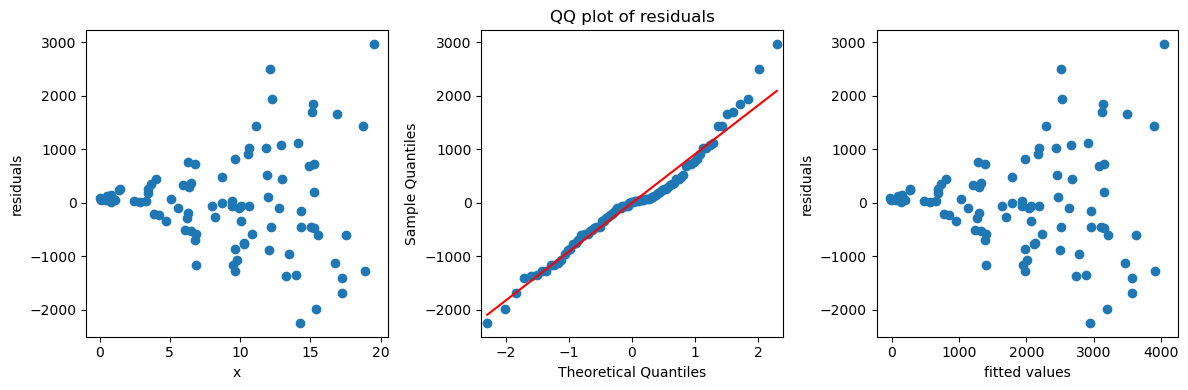

In [ ]:

fig, (ax0, ax1, ax2) = plt.subplots(1,3,figsize=(12,4))

# plot residuals versus x-values:
ax0.scatter(data["x"],data["residuals"])
ax0.set_xlabel("x")
ax0.set_ylabel("residuals")

# qq-plot of resiudals:
sm.qqplot(data["residuals"],ax=ax1, line='s')
ax1.set_title("QQ plot of residuals")

# plot residuals versus fitted values:
ax2.scatter(fittedvalues,data["residuals"])
ax2.set_xlabel("fitted values")
ax2.set_ylabel("residuals")

plt.tight_layout()
plt.show()

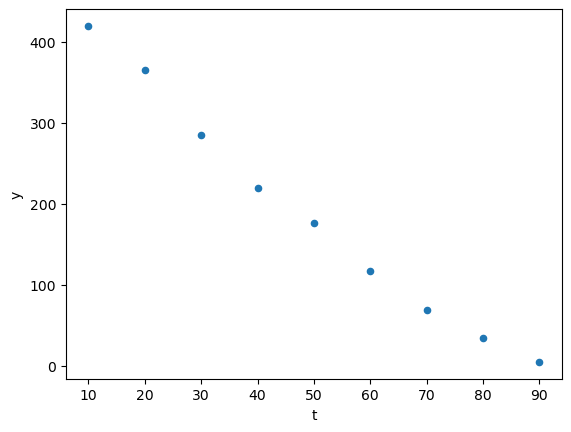

In [39]:
df = pd.DataFrame({
    't': [10, 20, 30, 40, 50, 60, 70, 80, 90],
    'y': [420, 365, 285, 220, 176, 117, 69, 34, 5]
})

df.plot.scatter(x='t', y='y')
plt.show()

In [41]:

Tbar = df["t"].mean()
ybar = df["y"].mean()

Sxx = np.sum((df["t"]-Tbar)**2)

beta1_hat = np.sum((df["y"]-ybar)*(df["t"]-Tbar))/Sxx

beta_0_hat = ybar - beta1_hat*Tbar

print(beta1_hat)
print(beta_0_hat)

-5.3133333333333335
453.55555555555554


In [42]:
#Theorem 5.4)

ybar = df['y'].mean()
Tbar = df['t'].mean()

# Compute Sxx to use in calculations:
Sxx = np.sum((df['t'] - Tbar)**2)

# Estimate parameters:
beta1_hat = np.sum((df['y'] - ybar) * (df['t'] - Tbar)) / Sxx
beta0_hat = ybar - beta1_hat * Tbar

print([beta0_hat, beta1_hat])

[np.float64(453.55555555555554), np.float64(-5.3133333333333335)]


In [ ]:
# Add residuals to dataframe:
df['residual'] = df['y'] - (beta0_hat + beta1_hat * df['t'])

# Estimate standard deviation of residuals:
n = len(df)
sigma_hat = np.sqrt(np.sum(df['residual']**2) / (n - 2))

# Estimate standard errors of parameters:
sigma_beta0_hat = sigma_hat * np.sqrt(1/n + Tbar**2 / Sxx)
sigma_beta1_hat = sigma_hat * np.sqrt(1/Sxx)

print([sigma_hat, sigma_beta0_hat, sigma_beta1_hat])

# Find the critical t-value with n-2 = 7 degrees of freedom:
t0975 = stats.t.ppf(0.975, df=7)

# Calculate the 95% confidence interval for the slope (beta1):
CI_beta1_lower = beta1_hat - t0975 * sigma_beta1_hat
CI_beta1_upper = beta1_hat + t0975 * sigma_beta1_hat

print([CI_beta1_lower, CI_beta1_upper])

[np.float64(19.81277445856666), np.float64(14.393646942675977), np.float64(0.2557818184006412)]
[np.float64(-5.9181612242399915), np.float64(-4.7085054424266755)]


In [ ]:
# Calculate the observed t-statistic:
tobs = beta1_hat / sigma_beta1_hat

# Calculate the two-sided p-value:
pvalue = 2 * stats.t.cdf(tobs, df=7)

print(pvalue)

1.505038769216071e-07


In [ ]:
fit = smf.ols('y ~ t', data=df).fit()
print(fit.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.982
No. Observations:                   9   F-statistic:                     431.5
Covariance Type:            nonrobust   Prob (F-statistic):           1.51e-07
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    453.5556     14.394     31.511      0.000     419.520     487.591
t             -5.3133      0.256    -20.773      0.000      -5.918      -4.709

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


In [ ]:
print(fit.pvalues)

Intercept    8.376549e-09
t            1.505039e-07
dtype: float64


In [ ]:

df = pd.DataFrame({
    'x': [0, 25, 50, 75, 100],
    'y': [14, 38, 54, 76, 95]
})

fit = smf.ols('y ~ x', data=df).fit()
print(fit.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.996
No. Observations:                   5   F-statistic:                     1071.
Covariance Type:            nonrobust   Prob (F-statistic):           6.27e-05
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     15.4000      1.497     10.290      0.002      10.637      20.163
x              0.8000      0.024     32.733      0.000       0.722       0.878

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


/Users/albertebechelholm/miniforge3/lib/python3.12/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [46]:
fit.conf_int(alpha=0.05)

,0,1
Intercept,10.636951,20.163049
x,0.722220,0.877780


In [ ]:
print(fit.get_prediction(pd.DataFrame({'x': [80]})).summary_frame(alpha=0.05))

   mean   mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  79.4  1.133255      75.793477      83.006523      72.27132      86.52868


In [ ]:
#Extract parameters from OLS
beta0_hat = fit.params['Intercept']
beta1_hat = fit.params['x']
sigma_hat = np.sqrt(fit.mse_resid)

#Calculate Sxx
n = len(df)
xbar = df['x'].mean()
Sxx = np.sum((df['x'] - xbar)**2)

# Calculate critical t-value
alpha = 0.05
t_critical = stats.t.ppf(1 - alpha/2, df=n-2)

# Predict yield at x = 80
x_new = 80
y_pred = beta0_hat + beta1_hat * x_new

# Calculate margin of error
margin_error = t_critical * sigma_hat * np.sqrt(
    1/n + (x_new - xbar)**2 / Sxx
)

#Calculate confidence interval
CI_lower = y_pred - margin_error
CI_upper = y_pred + margin_error

print(f"Predicted yield: {y_pred:.2f}")
print(f"Margin of error: {margin_error:.2f}")
print(f"95% CI: [{CI_lower:.2f}, {CI_upper:.2f}]")

Predicted yield: 79.40
Margin of error: 3.61
95% CI: [75.79, 83.01]


In [ ]:
# Extract residuals from the OLS model
residuals = fit.resid

# Calculate the upper quartile (75th percentile)
Q3 = residuals.quantile(0.75)

print(Q3)

0.5999999999999943
